In [1]:
import numpy as np
import pandas as pd
from tqdm.auto import tqdm
import matplotlib.pyplot as plt
import yaml
from pathlib import Path
from scipy.optimize import least_squares

from importlib import reload
from models import aux_funcs_01

reload(aux_funcs_01)
from models.aux_funcs_01 import *

ROOT = Path.cwd()

In [2]:
# Controls

OUTPUT_DIR = ROOT / "results/sample3/"

FG075_WEIGHT = 5.0

BASE_SEED = 1

Nruns = 2000

FMSURF = 2500

run_opt = True

THRESHOLD_SSE = 0.62 

In [3]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

In [4]:
# Inputs
with open("inputs/sample3_inputs.yaml", "r") as f:
    inputs = yaml.safe_load(f)
with open("inputs/sample3_experimentalData.yaml", "r") as f:
    experiments = yaml.safe_load(f)

In [5]:
inputs

{'core': {'k': 4.0384901436e-13, 'phi': 0.099, 'L': 0.245, 'D': 0.0381},
 'relPerm': {'swc': 0.36,
  'sgr': 0.0,
  'sor': 0.16,
  'nw_': 2.7,
  'ng_': 6.89,
  'no_': 3.0,
  'krw0': 0.365,
  'krg0': 0.278,
  'kro0': 0.574},
 'fluids': {'muw': 0.000603, 'mug': 1.25e-05, 'muo': 0.005, 'sigma': 1.0}}

In [6]:
fixed_rp_oil = inputs["relPerm"].copy()
fixed_rp_no_oil = {**fixed_rp_oil, "sor": 0.0}

# The oil-free forward model takes the parameters as an array.
rp_no_oil = np.array([
    fixed_rp_no_oil[key]
    for key in ("nw_", "ng_", "krw0", "krg0", "swc", "sgr", "sor")
], dtype=float)
rp_oil = np.array([
    fixed_rp_oil[key]
    for key in ("nw_", "ng_", "no_", "krw0", "krg0", "kro0", "swc", "sgr", "sor")
], dtype=float)
fixed_rp_oil, fixed_rp_no_oil


({'swc': 0.36,
  'sgr': 0.0,
  'sor': 0.16,
  'nw_': 2.7,
  'ng_': 6.89,
  'no_': 3.0,
  'krw0': 0.365,
  'krg0': 0.278,
  'kro0': 0.574},
 {'swc': 0.36,
  'sgr': 0.0,
  'sor': 0.0,
  'nw_': 2.7,
  'ng_': 6.89,
  'no_': 3.0,
  'krw0': 0.365,
  'krg0': 0.278,
  'kro0': 0.574})

In [7]:
# Reading models
rp_module_oil = load_module("relpermModel", "models/relativePermeabilityModels.py")
rp_module_noOil = load_module("relpermModel", "models/relativePermeabilityModels.py")
foam_module_oil = load_module("foamModel", "models/foamModels.py")
foam_module_noOil = load_module("foamModel", "models/foamModels.py")

foam_module_oil.coreyBrooks3ph = rp_module_oil.coreyBrooks3ph(fixed_rp_oil)
foam_module_noOil.coreyBrooks3ph = rp_module_noOil.coreyBrooks3ph(fixed_rp_no_oil)


In [8]:
# Reading experiments
CONCENTRATIONS = (625, 1250, 2500)

# DIFFERENT SURFACTANT CONCENTRATIONS

scans = {}
velocity_by_concentration = {}
frames = []
for concentration in CONCENTRATIONS:
    experiment = experiments[f"FQS_{concentration}mgL"]
    scan_all = np.array(experiment["data"], dtype=float)
    scans[concentration] = scan_all

    velocity = float(experiment["ut"]) * 0.3048 / 86400 # convert to m/s
    velocity_by_concentration[concentration] = velocity
    frames.append(pd.DataFrame({
        "experiment": f"{concentration} mg/L", "Cs_mg_L": concentration,
        "fg": scan_all[:, 0], "muApp_cP": scan_all[:, 1], "ut": velocity,
    }))
surf_observations = pd.concat(frames, ignore_index=True)

# separating data
fg_obs = surf_observations["fg"].to_numpy()
mu_obs = surf_observations["muApp_cP"].to_numpy()
cs_obs = surf_observations["Cs_mg_L"].to_numpy(dtype=float)
ut_obs = surf_observations["ut"].to_numpy()
is_foam = np.ones(len(fg_obs), dtype=bool)
so_viscosity_obs = np.zeros_like(fg_obs, dtype=float)
surf_observations["So"] = so_viscosity_obs

# Oil observations: muApp is stored in Pa.s and Cs in mg/L in the YAML.
oil_experiment = experiments["oil_observations_preprocessed"]
oil_observations = pd.DataFrame(
    oil_experiment["data"],
    columns=["So", "Sw", "Sg", "muApp", "fg"],
)
oil_observations["Cs_mg_L"] = float(oil_experiment["surfactant_concentration_mg_L"])
cs_oil_obs = oil_observations["Cs_mg_L"].to_numpy(dtype=float)
so_oil_obs = oil_observations["So"].to_numpy(dtype=float)
sw_oil_obs = oil_observations["Sw"].to_numpy(dtype=float)
sg_oil_obs = oil_observations["Sg"].to_numpy(dtype=float)
mu_oil_obs = oil_observations["muApp"].to_numpy(dtype=float) * 1000
fg_oil_obs = oil_observations["fg"].to_numpy(dtype=float)

# Weights and normalization scales.
point_weights = np.where(np.isclose(fg_obs, 0.75), FG075_WEIGHT, 1.0)
mu_scale = float(mu_obs.max())
mu_oil_scale = float(mu_oil_obs.max())


In [9]:
display(surf_observations)
display(oil_observations)
print(f"Surfactant viscosity scale: {mu_scale:.2f} cP; oil viscosity scale: {mu_oil_scale:.2f} cP")


,experiment,Cs_mg_L,fg,muApp_cP,ut,So
0,625 mg/L,625,0.25,50.42,0.000007,0.0
1,625 mg/L,625,0.50,164.64,0.000007,0.0
2,625 mg/L,625,0.70,253.69,0.000007,0.0
3,625 mg/L,625,0.75,267.24,0.000007,0.0
4,625 mg/L,625,0.85,214.97,0.000007,0.0
5,625 mg/L,625,0.90,193.68,0.000007,0.0
6,625 mg/L,625,1.00,48.49,0.000007,0.0
7,1250 mg/L,1250,0.25,414.36,0.000007,0.0
8,1250 mg/L,1250,0.50,789.92,0.000007,0.0
9,1250 mg/L,1250,0.70,1012.54,0.000007,0.0


,So,Sw,Sg,muApp,fg,Cs_mg_L
0,0.2191,0.490931,0.289969,0.027241,0.5,5000.0
1,0.2724,0.512464,0.215136,0.017338,0.5,5000.0
2,0.3115,0.533843,0.154657,0.011735,0.5,5000.0
3,0.3541,0.573828,0.072072,0.006597,0.5,5000.0


Surfactant viscosity scale: 2079.19 cP; oil viscosity scale: 27.24 cP


## Objective function

$$\chi^2(\theta)=\sum_k w_k\left[\frac{\mu_{surf,k}^{exp}-\mu_{surf,k}(\theta;S_o=0)}{\max_j\mu_{surf,j}^{exp}}\right]^2+\sum_i\left[\frac{\mu_{oil,i}^{exp}-\mu_{oil,i}(\theta;S_{w,i},S_{g,i},S_{o,i},C_{s,i})}{\max_j\mu_{oil,j}^{exp}}\right]^2+\sum_i\left[f_{g,i}^{exp}-f_{g,i}(\theta;S_{w,i},S_{g,i},S_{o,i},C_{s,i})\right]^2.$$

The oil gas-fraction targets are read from the YAML ($f_g^{exp}=0.5$ for all oil observations). Their dimensionless residuals use unit weight. Both viscosity blocks use cP. Oil data use the relative permeability parameters from the YAML; oil-free scans use the same parameters with $s_{or}=0$. The oil observations provide fixed phase saturations and read $C_s$ from `oil_observations_preprocessed.surfactant_concentration_mg_L` in the YAML (currently 5000 mg/L). Both oil residual blocks use $F_{surf}(C_s)$; with $fmsurf=2500$ mg/L, this gives $F_{surf}=1$.

$$\mu_{oil}=\left[\frac{k_{rw}}{\mu_w}+\frac{k_{ro}}{\mu_o}+\frac{k_{rg}/\mu_g}{1+fmmob\,F_{dry}(S_w)\,F_{oil}(S_o)\,F_{surf}(C_s)}\right]^{-1},\qquad F_{dry}=\frac12+\frac{\arctan[epdry(S_w-fmdry)]}{\pi}.$$

The oil-free scans retain the existing fractional-flow calculation. Both oil and oil-free predictions use the surfactant factor:

$$F_{surf}(C_s)=\begin{cases}(C_s/fmsurf)^{epsurf},&C_s<fmsurf,\\1,&C_s\geq fmsurf.\end{cases}$$

$$F_{oil}(S_o)=\begin{cases}1,&S_o<floil,\\((fmoil-S_o)/(fmoil-floil))^{epoil},&floil\leq S_o\leq fmoil,\\0,&S_o>fmoil.\end{cases}$$


In [10]:
# Fitting bounds
SAT_EPS = 1e-6

bounds = {
    "fmmob": (10, 1e7),
    "epdry": (10, 1e4),
    "fmdry": (inputs["relPerm"]["swc"], 1 - inputs["relPerm"]["swc"] - inputs["relPerm"]["sor"]),
    "epsurf": (1e-3, 10),
    "epoil": (1e-3, 100),
    "fmoil": (0, 1-SAT_EPS),
    "floil": (SAT_EPS, 1)
}
names = list(bounds.keys())
print(names)

lower_bounds = np.array([b[0] for b in bounds.values()])
upper_bounds = np.array([b[1] for b in bounds.values()])

# Os quatro parâmetros de espuma do bloco de surfactante usam coordenadas
# logarítmicas. 
# Óleo usa `(log(epoil), floil, qoil)` com `fmoil=floil+(1-floil)*qoil`,
# impondo `epoil>0` e `0<=floil<fmoil<=1`.
zlo = np.r_[np.log(lower_bounds[:5]),lower_bounds[5:]]
zhi = np.r_[np.log(upper_bounds[:5]),upper_bounds[5:]]

internal_names = [f"log({name})" for name in ["fmmob", "epdry", "fmdry", "epsurf"]]+["log(epoil)", "floil", "qoil"]
internal_names


['fmmob', 'epdry', 'fmdry', 'epsurf', 'epoil', 'fmoil', 'floil']


['log(fmmob)',
 'log(epdry)',
 'log(fmdry)',
 'log(epsurf)',
 'log(epoil)',
 'floil',
 'qoil']

In [11]:
# Running the optimization
if run_opt:
    seeds = np.arange(BASE_SEED, BASE_SEED + Nruns) 
    parameter_rows, initial_rows, diagnostic_rows = [], [], []
    best, best_seed, best_sse = None, None, np.inf

    initial_reference = np.array([2005.5, 1000., 0.5, 1.0, 1., .5, .05])
    start_margin = np.minimum(1e-6, .1*(zhi-zlo))
    initial_z = np.clip(encode(initial_reference, internal_names), zlo+start_margin, zhi-start_margin)


    for run, seed in enumerate(tqdm(seeds, desc="Optimization runs")):
        z0 = make_initial(int(seed), initial_z, zlo, zhi, start_margin, so_oil_obs, SAT_EPS)
        initial_rows.append(decode(z0))
        fitted = np.full(len(names), np.nan)
        diagnostic = dict(seed=int(seed), success=False, surf_SSE=np.nan, oil_SSE=np.nan, oil_fg_SSE=np.nan,
                            weighted_normalized_SSE=np.nan, status=-99, nfev=0, optimality=np.nan, message="")

        try:
            fit = least_squares(residual, z0, args=(foam_module_noOil, point_weights, mu_obs, so_oil_obs, mu_scale, fg_obs, is_foam, ut_obs, cs_obs, rp_no_oil, FMSURF, inputs, 
                                                    foam_module_oil, mu_oil_obs, mu_oil_scale, sw_oil_obs, sg_oil_obs, so_oil_obs, fg_oil_obs, cs_oil_obs),
                                bounds=(zlo, zhi), max_nfev=3000,
                                ftol=1e-10, xtol=1e-10, gtol=1e-9, x_scale="jac",
                                method="trf")
            fitted = decode(fit.x)
            components = objective_components(fitted, foam_module_noOil, point_weights, mu_obs, so_oil_obs, mu_scale, fg_obs, is_foam, ut_obs, cs_obs, rp_no_oil, FMSURF, inputs, 
                                                    foam_module_oil, mu_oil_obs, mu_oil_scale, sw_oil_obs, sg_oil_obs, so_oil_obs, fg_oil_obs, cs_oil_obs)
            diagnostic.update(components, success=bool(fit.success), status=int(fit.status), nfev=int(fit.nfev), optimality=float(fit.optimality), message=str(fit.message))
            if fit.success and np.isfinite(fitted).all() and components["weighted_normalized_SSE"] < best_sse:
                        best, best_seed, best_sse = fit, int(seed), components["weighted_normalized_SSE"]

        except (ValueError, FloatingPointError, RuntimeError) as exc:
            diagnostic["message"] = f"{type(exc).__name__}: {exc}"
            print(diagnostic["message"])

        parameter_rows.append(fitted)
        diagnostic_rows.append(diagnostic)

    # Saving results
    params_df = pd.DataFrame(parameter_rows, columns=names, index=pd.Index(seeds, name="seed"))
    initial_params_df = pd.DataFrame(initial_rows, columns=names, index=params_df.index)
    diagnostics_df = pd.DataFrame(diagnostic_rows).set_index("seed")

    for filename, table in {
        "experimental_parameters": params_df,
        "experimental_initial_parameters": initial_params_df,
        "experimental_diagnostics": diagnostics_df,
    }.items():
        table.to_csv(OUTPUT_DIR / f"{filename}.csv")

else:
    # Load previous results
    params_df = pd.read_csv(OUTPUT_DIR / "experimental_parameters.csv", index_col="seed")
    initial_params_df = pd.read_csv(OUTPUT_DIR / "experimental_initial_parameters.csv", index_col="seed")
    diagnostics_df = pd.read_csv(OUTPUT_DIR / "experimental_diagnostics.csv", index_col="seed")

diagnostics_df.head()


Optimization runs:   0%|          | 0/2000 [00:00<?, ?it/s]

,success,surf_SSE,oil_SSE,oil_fg_SSE,weighted_normalized_SSE,status,nfev,optimality,message
seed,,,,,,,,,
1,True,0.109305,0.143536,0.361913,0.614754,2,19,4.592003e-05,`ftol` termination condition is satisfied.
2,True,0.109298,1.139958,0.643708,1.892964,2,37,5.133272e-06,`ftol` termination condition is satisfied.
3,True,0.109298,1.139958,0.643708,1.892964,2,41,9.615208e-08,`ftol` termination condition is satisfied.
4,True,0.109305,0.143536,0.361913,0.614754,2,27,3.099318e-05,`ftol` termination condition is satisfied.
5,True,0.109298,1.139958,0.643708,1.892964,2,33,3.605275e-06,`ftol` termination condition is satisfied.


In [12]:
# select runs which values < threshold_sse

values = diagnostics_df["weighted_normalized_SSE"]

select = diagnostics_df["success"].fillna(False).astype(bool) & np.isfinite(values) & (values < THRESHOLD_SSE)

parameter_statistics = diagnostics_df[["surf_SSE", "oil_SSE", "oil_fg_SSE", "weighted_normalized_SSE"]].describe(percentiles=[.25, .5, .75]).T.rename(
    columns={"25%": "q25", "50%": "median", "75%": "q75"})
display(parameter_statistics)

,count,mean,std,min,q25,median,q75,max
surf_SSE,2000.0,0.159063,0.703803,0.109298,0.109298,0.109298,0.109305,10.363619
oil_SSE,2000.0,0.795317,0.496879,0.142742,0.143536,1.139958,1.139958,1.646622
oil_fg_SSE,2000.0,0.554135,0.155814,0.356104,0.361913,0.643708,0.643708,0.999297
weighted_normalized_SSE,2000.0,1.508515,0.937534,0.614754,0.614754,1.892964,1.892964,11.549373


count    6.880000e+02
mean     6.147540e-01
std      4.534857e-12
min      6.147540e-01
25%      6.147540e-01
50%      6.147540e-01
75%      6.147540e-01
max      6.147540e-01
Name: weighted_normalized_SSE, dtype: float64


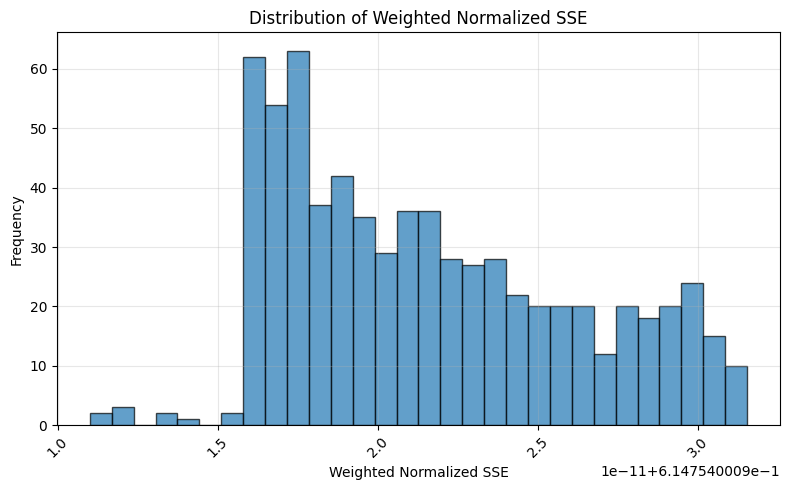

In [13]:
from matplotlib.ticker import MultipleLocator

stat = diagnostics_df["weighted_normalized_SSE"].loc[select]
print(stat.describe())

fig, ax = plt.subplots(figsize=(8, 5))

ax.hist(
    diagnostics_df["weighted_normalized_SSE"].loc[select],
    bins=30,
    edgecolor="black",
    alpha=0.7
)

ax.set_xlabel("Weighted Normalized SSE")
ax.set_ylabel("Frequency")
ax.set_title("Distribution of Weighted Normalized SSE")
ax.tick_params(axis="x", labelrotation=45)
ax.grid(alpha=0.3)
# ax.xaxis.set_major_locator(MultipleLocator(0.1))

plt.tight_layout()
plt.show()

In [14]:
params_df.head()

parameter_statistics = params_df[select].describe(percentiles=[.25, .5, .75]).T.rename(
    columns={"25%": "q25", "50%": "median", "75%": "q75"})
display(parameter_statistics)


,count,mean,std,min,q25,median,q75,max
fmmob,688.0,5.959547e+04,6.828849e-03,5.959545e+04,5.959547e+04,5.959547e+04,5.959548e+04,5.959549e+04
epdry,688.0,1.072447e+02,3.146778e-05,1.072445e+02,1.072446e+02,1.072447e+02,1.072447e+02,1.072448e+02
fmdry,688.0,3.776504e-01,2.690413e-09,3.776504e-01,3.776504e-01,3.776504e-01,3.776504e-01,3.776504e-01
epsurf,688.0,1.548843e+00,7.815438e-08,1.548843e+00,1.548843e+00,1.548843e+00,1.548844e+00,1.548844e+00
epoil,688.0,9.536800e+00,5.575240e-05,9.536727e+00,9.536748e+00,9.536766e+00,9.536854e+00,9.536880e+00
fmoil,688.0,4.085858e-01,1.520786e-06,4.085838e-01,4.085843e-01,4.085848e-01,4.085872e-01,4.085879e-01
floil,688.0,9.081914e-17,1.190697e-15,1.332552e-26,2.704059e-23,3.087687e-22,5.270442e-21,2.627023e-14


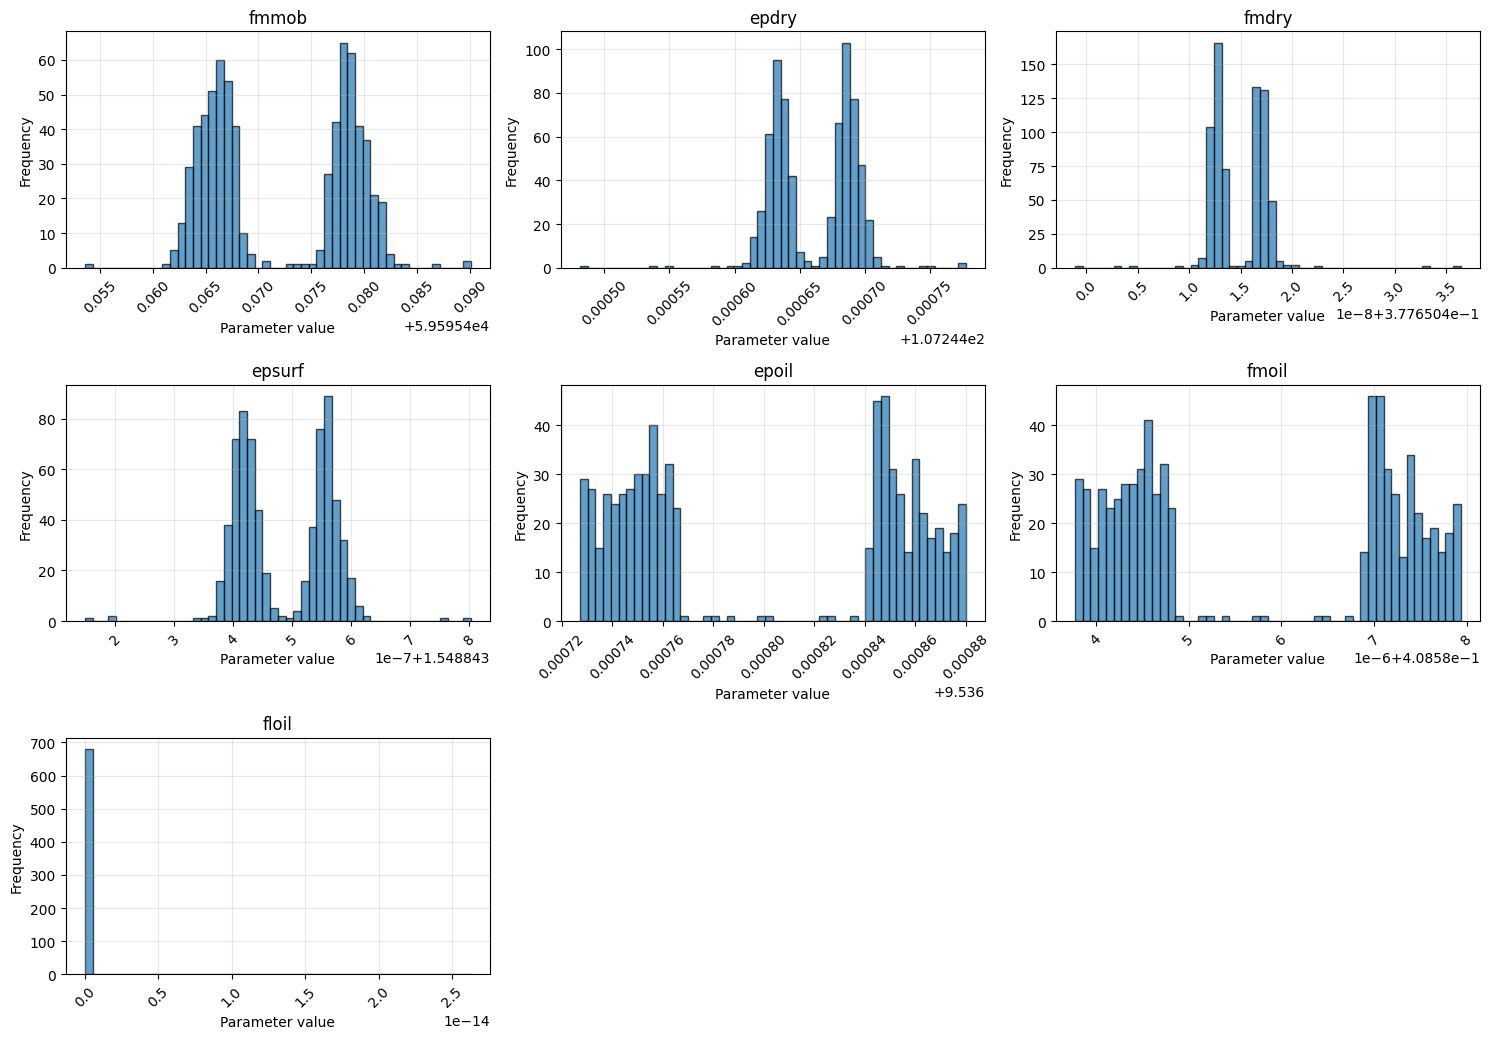

In [15]:
# Filter selected rows
params_selected = params_df.loc[select]

ncols = 3
nrows = int(np.ceil(len(params_selected.columns) / ncols))

fig, axes = plt.subplots(nrows, ncols, figsize=(15, 3.5 * nrows))
axes = np.ravel(axes)

for ax, col in zip(axes, params_selected.columns):
    ax.hist(params_selected[col], bins=50, edgecolor="black", alpha=0.7)
    ax.set_title(col)
    ax.set_xlabel("Parameter value")
    ax.set_ylabel("Frequency")
    ax.grid(alpha=0.3)
    ax.tick_params(axis="x", labelrotation=45)

# Remove unused subplots
for ax in axes[len(params_selected.columns):]:
    ax.remove()

plt.tight_layout()
plt.show()

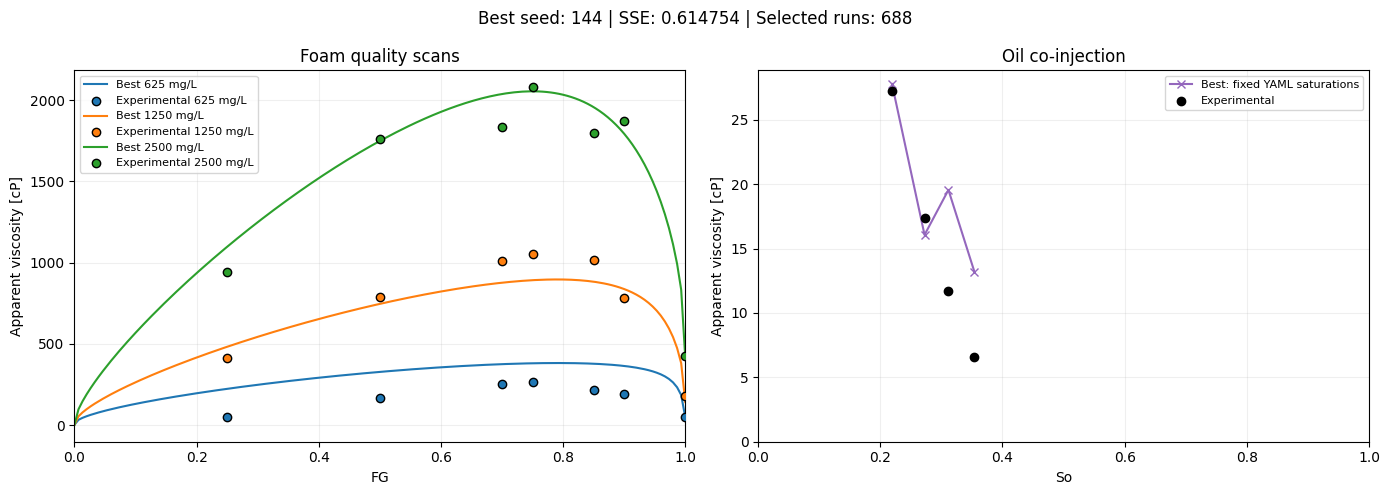

In [23]:
# Parâmetros físicos das rodadas selecionadas
params_selected = params_df.loc[select, names].copy()
params_selected = params_selected.loc[
    np.isfinite(params_selected).all(axis=1)
]

best_seed = diagnostics_df.loc[
    params_selected.index, "weighted_normalized_SSE"
].idxmin()

theta = params_selected.loc[best_seed].to_numpy(dtype=float)
median_theta = params_selected.median().to_numpy(dtype=float)

sw_grid = np.linspace(0, 1, 151)


def scan(p, cs):
    return predict(
        p,
        sw_grid,
        np.ones(sw_grid.size, dtype=bool),
        np.full(sw_grid.size, velocity_by_concentration[cs]),
        np.full(sw_grid.size, cs, dtype=float),
        foam_module_noOil,
        rp_no_oil,
        FMSURF,
        inputs,
    )[0]


fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# # Selected runs
# for _, row in params_selected.iterrows():
#     p = row.to_numpy(dtype=float)

#     for i, cs in enumerate(CONCENTRATIONS):
#         axes[0].plot(
#             sw_grid, scan(p, cs),
#             color=f"C{i}", alpha=0.15, zorder=1,
#         )

#     axes[1].plot(
#         so_oil_obs,
#         predict_oil_viscosity(p, foam_module_oil, sw_oil_obs, sg_oil_obs, so_oil_obs, inputs, cs_oil_obs, FMSURF),
#         color="gray", alpha=0.15, zorder=1,
#     )

# Best fit, median and experimental data
for i, cs in enumerate(CONCENTRATIONS):
    color = f"C{i}"

    axes[0].plot(
        sw_grid, scan(theta, cs),
        color=color, label=f"Best {cs} mg/L", zorder=2,
    )
    # axes[0].plot(
    #     sw_grid, scan(median_theta, cs),
    #     color=color, ls="--", label=f"Median {cs} mg/L", zorder=2,
    # )
    axes[0].scatter(
        scans[cs][:, 0], scans[cs][:, 1],
        color=color, edgecolor="black",
        label=f"Experimental {cs} mg/L", zorder=3,
    )

# Oil
axes[1].plot(
    so_oil_obs,
    predict_oil_viscosity(theta, foam_module_oil, sw_oil_obs, sg_oil_obs, so_oil_obs, inputs, cs_oil_obs, FMSURF),
    color="tab:purple", marker="x", label="Best: fixed YAML saturations", zorder=2,
)
# axes[1].plot(
#     so_oil_obs,
#     predict_oil_viscosity(median_theta, foam_module_oil, sw_oil_obs, sg_oil_obs, so_oil_obs, inputs, cs_oil_obs, FMSURF),
#     color="tab:red", ls="--", label="Median: fixed YAML saturations", zorder=2,
# )
axes[1].scatter(
    so_oil_obs, mu_oil_obs,
    color="black", label="Experimental", zorder=3,
)

# Formatting
axes[0].set(
    xlabel="FG",
    ylabel="Apparent viscosity [cP]",
    title="Foam quality scans",
    xlim=(0, 1),
)
axes[1].set(
    xlabel="So",
    ylabel="Apparent viscosity [cP]",
    title="Oil co-injection",
    xlim=(0, 1),
    ylim=(0, None),
)

for ax in axes:
    ax.legend(fontsize=8)
    ax.grid(alpha=0.2)

fig.suptitle(
    f"Best seed: {best_seed} | "
    f"SSE: {diagnostics_df.loc[best_seed, 'weighted_normalized_SSE']:.8g} | "
    f"Selected runs: {len(params_selected)}"
)

fig.tight_layout()
plt.show()

In [17]:
for label, parameters in (("WITH OIL", fixed_rp_oil), ("WITHOUT OIL", fixed_rp_no_oil)):
    print(f"RELATIVE PERMEABILITY: {label}")
    for name, value in parameters.items():
        print(f"  {name:8s} = {value:.10g}")

foam_params = dict(zip(
    ("fmmob", "epdry", "fmdry", "epsurf", "epoil", "fmoil", "floil"),
    theta,
))
foam_params["fmsurf"] = FMSURF

print("\nESPUMA")
for name in (
    "fmmob", "fmdry", "epdry", "fmsurf",
    "epsurf", "epoil", "fmoil", "floil",
):
    print(f"  {name:8s} = {foam_params[name]:.10g}")

print("Foil_Act = True; Fsurf_Act = True; Fshear_Act = False")

RELATIVE PERMEABILITY: WITH OIL
  swc      = 0.36
  sgr      = 0
  sor      = 0.16
  nw_      = 2.7
  ng_      = 6.89
  no_      = 3
  krw0     = 0.365
  krg0     = 0.278
  kro0     = 0.574
RELATIVE PERMEABILITY: WITHOUT OIL
  swc      = 0.36
  sgr      = 0
  sor      = 0
  nw_      = 2.7
  ng_      = 6.89
  no_      = 3
  krw0     = 0.365
  krg0     = 0.278
  kro0     = 0.574

ESPUMA
  fmmob    = 59595.47897
  fmdry    = 0.3776504181
  epdry    = 107.2446382
  fmsurf   = 2500
  epsurf   = 1.548843551
  epoil    = 9.536801586
  fmoil    = 0.4085857969
  floil    = 3.530220112e-21
Foil_Act = True; Fsurf_Act = True; Fshear_Act = False


In [18]:
foam_params

{'fmmob': 59595.47897166264,
 'epdry': 107.24463818001077,
 'fmdry': 0.3776504181067176,
 'epsurf': 1.548843551194907,
 'epoil': 9.53680158587931,
 'fmoil': 0.40858579693034613,
 'floil': 3.530220112461825e-21,
 'fmsurf': 2500}

In [19]:
# foam_params['epoil'] = 1.4
# foam_params['fmoil'] = 0.4

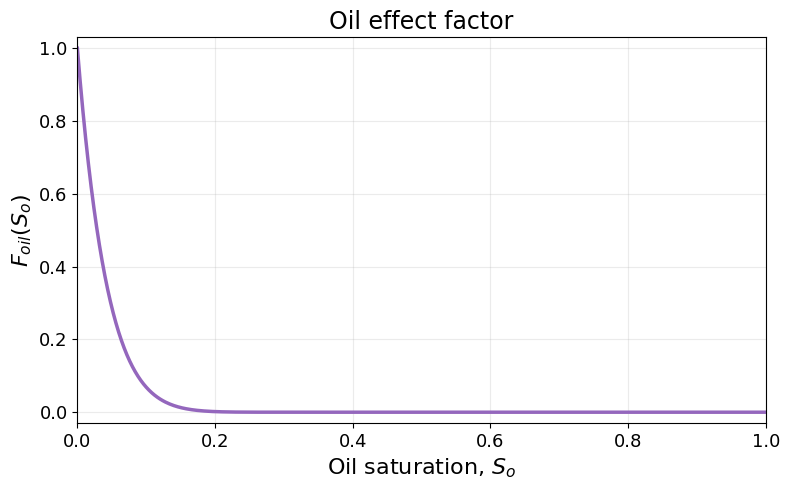

In [20]:
# Oil effect factor using the fitted foam parameters.
So = np.linspace(0.0, 1.0, 501)
theta_foil = [
    foam_params[name]
    for name in ("fmmob", "epdry", "fmdry", "epsurf", "epoil", "fmoil", "floil")
]
Foil = predict_oil(theta_foil, foam_module_oil, So)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(So, Foil, color="tab:purple", linewidth=2.5)
ax.set_xlabel(r"Oil saturation, $S_o$", fontsize=16)
ax.set_ylabel(r"$F_{oil}(S_o)$", fontsize=16)
ax.set_title("Oil effect factor", fontsize=17)
ax.set_xlim(0, 1)
ax.set_ylim(-0.03, 1.03)
ax.tick_params(labelsize=13)
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()


    So  fg_calculated  muApp_calculated_cP         Foil  fmmob * Foil
0.2191       0.490091            27.781305 6.569107e-04     39.148908
0.2724       0.536814            16.061672 2.815148e-05      1.677701
0.3115       0.166713            19.556856 1.116398e-06      0.066532
0.3541       0.000621            13.185650 4.521672e-09      0.000269


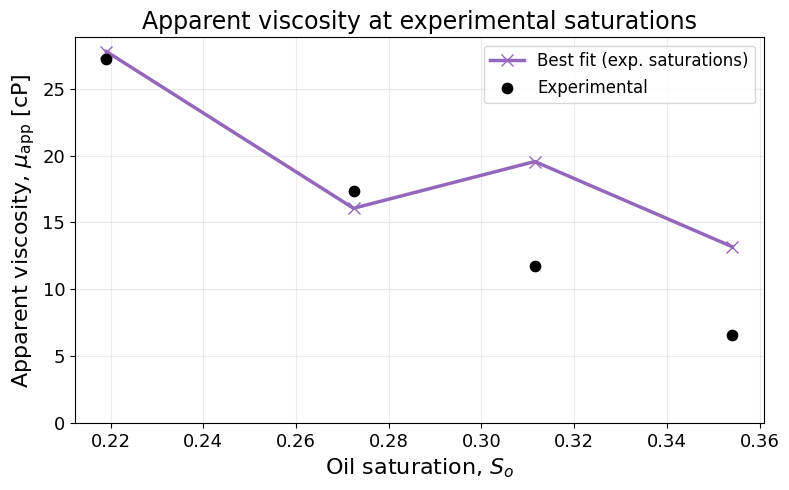

In [21]:
# Evaluate the fitted model only at the experimental YAML saturations.
theta_mu = np.array([
    foam_params[name]
    for name in ("fmmob", "epdry", "fmdry", "epsurf", "epoil", "fmoil", "floil")
])
fg_oil_fit, muApp_oil_fit = evaluate_oil_state(
    theta_mu, foam_module_oil, sw_oil_obs, sg_oil_obs, so_oil_obs, inputs, cs_oil_obs, FMSURF,
)
foil_oil_fit = predict_oil(theta_mu, foam_module_oil, so_oil_obs)
print(pd.DataFrame({
    "So": so_oil_obs,
    "fg_calculated": fg_oil_fit,
    "muApp_calculated_cP": muApp_oil_fit,
    "Foil": foil_oil_fit,
    "fmmob * Foil": foam_params["fmmob"] * foil_oil_fit,
}).to_string(index=False))

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(so_oil_obs, muApp_oil_fit, color="tab:purple", marker="x",
        linewidth=2.5, markersize=8, label="Best fit (exp. saturations)")
ax.scatter(so_oil_obs, mu_oil_obs, color="black", s=55, zorder=3,
           label="Experimental")
ax.set_xlabel(r"Oil saturation, $S_o$", fontsize=16)
ax.set_ylabel(r"Apparent viscosity, $\mu_{\mathrm{app}}$ [cP]", fontsize=16)
ax.set_title("Apparent viscosity at experimental saturations", fontsize=17)
ax.set_ylim(bottom=0)
ax.tick_params(labelsize=13)
ax.legend(fontsize=12)
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()


      So       Sw       Sg  Sw_reference  Sg_reference  delta_Sw  delta_Sg  valid_fg         selection  fg_calculated     fg_error  muApp_calculated_cP      mobg      mobw     mobo     Fdry         Foil  fmmob * Foil
0.219100 0.490038 0.290862      0.491048      0.289852 -0.001010  0.001010      True         fg_target       0.500000 3.885781e-16            27.743285 18.022379 17.808099 0.214279 0.973651 6.569107e-04     39.148908
0.220464 0.490799 0.288738      0.491600      0.287937 -0.000801  0.000801      True         fg_target       0.500000 6.661338e-16            27.292433 18.320096 18.090640 0.229457 0.973827 6.131860e-04     36.543111
0.221827 0.491561 0.286612      0.492151      0.286022 -0.000590  0.000590      True         fg_target       0.500000 2.220446e-16            26.850133 18.621882 18.376547 0.245334 0.974002 5.720849e-04     34.093671
0.223191 0.492324 0.284485      0.492703      0.284106 -0.000379  0.000379      True         fg_target       0.500000 2.220446e-16  

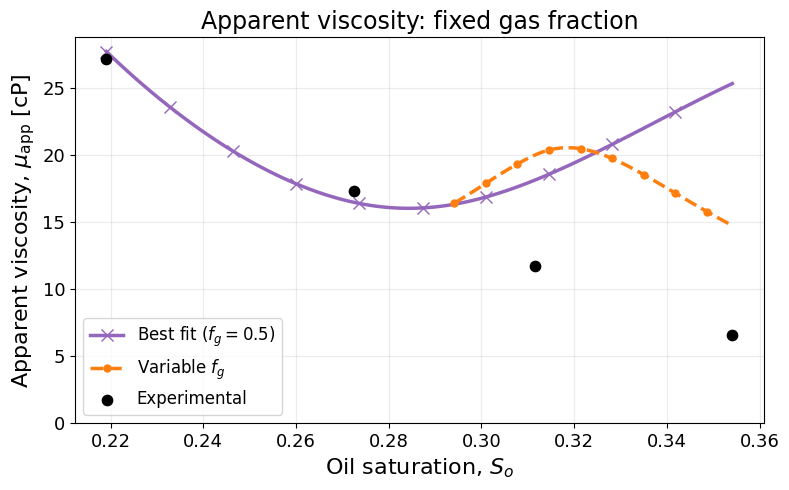

In [22]:
# Reconstruct oil states near the supplied experimental saturation path.
theta_mu = np.array([
    foam_params[name]
    for name in ("fmmob", "epdry", "fmdry", "epsurf", "epoil", "fmoil", "floil")
])
so_oil_grid = np.linspace(so_oil_obs.min(), so_oil_obs.max(), 100)
cs_oil_grid = float(experiments["oil_observations_preprocessed"]["surfactant_concentration_mg_L"])
fg_target = 0.5
fg_tolerance = 1e-6

# Experimental points supplied in the chat; muApp is in Pa.s.
oil_saturation_reference = pd.DataFrame([
    [0.2191, 0.491048, 0.289852, 0.027176, 0.5],
    [0.2724, 0.512606, 0.214994, 0.017297, 0.5],
    [0.3115, 0.534012, 0.154488, 0.011707, 0.5],
    [0.3541, 0.574038, 0.071862, 0.006581, 0.5],
], columns=["So", "Sw", "Sg", "muApp", "fg"]).sort_values("So")

# Maximum absolute distance from interpolated experimental Sw AND Sg.
SATURATION_TOLERANCE = 0.01
N_SATURATION_CANDIDATES = 201
sw_oil_reference = np.interp(
    so_oil_grid, oil_saturation_reference["So"], oil_saturation_reference["Sw"],
)
sg_oil_reference = np.interp(
    so_oil_grid, oil_saturation_reference["So"], oil_saturation_reference["Sg"],
)

# Generate candidate states only near the experimental saturation path.
# Sg = 1 - So - Sw, so the Sg bounds also constrain the Sw interval.
# The solver intersects these bounds with the physical residual limits.
sw_candidate_min = np.maximum(
    sw_oil_reference - SATURATION_TOLERANCE,
    1 - so_oil_grid - (sg_oil_reference + SATURATION_TOLERANCE),
)
sw_candidate_max = np.minimum(
    sw_oil_reference + SATURATION_TOLERANCE,
    1 - so_oil_grid - (sg_oil_reference - SATURATION_TOLERANCE),
)
# First try to satisfy fg=0.5 within the local saturation interval.
fg_oil_grid, sw_oil_grid, muApp_oil_grid = predict_oil_at_fg(
    theta_mu, so_oil_grid, fixed_rp_oil, foam_module_oil, inputs,
    cs_oil_grid, FMSURF, fg_target=fg_target, fg_tolerance=fg_tolerance,
    sw_bounds=(sw_candidate_min, sw_candidate_max),
)
# Preserve exact-fg solutions. For missing roots, search only nearby states.
# Select the smallest fg error; ties favor proximity to the reference pair.
matches_fg_target = np.isfinite(fg_oil_grid) & np.isclose(
    fg_oil_grid, fg_target, atol=fg_tolerance, rtol=0,
)
for i in np.flatnonzero(~matches_fg_target):
    so = so_oil_grid[i]
    sw_min = max(fixed_rp_oil["swc"], sw_candidate_min[i])
    sw_max = min(1 - so - fixed_rp_oil["sgr"], sw_candidate_max[i])
    if so < fixed_rp_oil["sor"] or sw_min > sw_max:
        continue
    sw_candidates = np.unique(np.r_[
        np.linspace(sw_min, sw_max, N_SATURATION_CANDIDATES),
        np.clip(sw_oil_reference[i], sw_min, sw_max),
    ])
    sg_candidates = 1 - so - sw_candidates
    fg_candidates, mu_candidates = evaluate_oil_state(
        theta_mu, foam_module_oil, sw_candidates, sg_candidates,
        np.full_like(sw_candidates, so), inputs, cs_oil_grid, FMSURF,
    )
    feasible = (np.isfinite(fg_candidates) & np.isfinite(mu_candidates)
                & (mu_candidates > 0))
    if not feasible.any():
        continue
    candidate_ids = np.flatnonzero(feasible)
    distance = ((sw_candidates[feasible] - sw_oil_reference[i]) ** 2
                + (sg_candidates[feasible] - sg_oil_reference[i]) ** 2)
    order = np.lexsort((distance, np.abs(fg_candidates[feasible] - fg_target)))
    chosen = candidate_ids[order[0]]
    sw_oil_grid[i] = sw_candidates[chosen]
    fg_oil_grid[i] = fg_candidates[chosen]
    muApp_oil_grid[i] = mu_candidates[chosen]

sg_oil_grid = 1 - so_oil_grid - sw_oil_grid
foil_oil_grid = predict_oil(theta_mu, foam_module_oil, so_oil_grid)
fdry_oil_grid = 0.5 + np.arctan(theta_mu[1] * (sw_oil_grid - theta_mu[2])) / np.pi
fsurf_oil_grid = min(cs_oil_grid / FMSURF, 1.0) ** theta_mu[3]
valid_oil_grid = np.isfinite(muApp_oil_grid)
fallback_oil_grid = valid_oil_grid & ~matches_fg_target

# Full fg=0.5 curve from the original approach: use all physical saturations.
fg_oil_full, sw_oil_full, muApp_oil_full = predict_oil_at_fg(
    theta_mu, so_oil_grid, fixed_rp_oil, foam_module_oil, inputs,
    cs_oil_grid, FMSURF, fg_target=fg_target, fg_tolerance=fg_tolerance,
)
sg_oil_full = 1 - so_oil_grid - sw_oil_full

# Phase mobilities [1/(Pa.s)], including foam resistance in the gas phase.
rp_oil_grid = foam_module_oil.coreyBrooks3ph
mrf_oil_grid = 1.0 + theta_mu[0] * fdry_oil_grid * foil_oil_grid * fsurf_oil_grid
mobg_oil_grid = rp_oil_grid.krg(sg_oil_grid) / (inputs["fluids"]["mug"] * mrf_oil_grid)
mobw_oil_grid = rp_oil_grid.krw(sw_oil_grid) / inputs["fluids"]["muw"]
mobo_oil_grid = rp_oil_grid.kro(so_oil_grid) / inputs["fluids"]["muo"]

oil_fg_scan = pd.DataFrame({
    "So": so_oil_grid,
    "Sw": sw_oil_grid,
    "Sg": sg_oil_grid,
    "Sw_reference": sw_oil_reference,
    "Sg_reference": sg_oil_reference,
    "delta_Sw": sw_oil_grid - sw_oil_reference,
    "delta_Sg": sg_oil_grid - sg_oil_reference,
    "valid_fg": matches_fg_target,
    "selection": np.select(
        [matches_fg_target, fallback_oil_grid],
        ["fg_target", "near_experimental"], default="no_feasible_state",
    ),
    # "Cs_mg_L": cs_oil_grid,
    "fg_calculated": fg_oil_grid,
    "fg_error": np.abs(fg_oil_grid - fg_target),
    "muApp_calculated_cP": muApp_oil_grid,
    "mobg": mobg_oil_grid,
    "mobw": mobw_oil_grid,
    "mobo": mobo_oil_grid,
    "Fdry": fdry_oil_grid,
    # "Fsurf": fsurf_oil_grid,
    "Foil": foil_oil_grid,
    "fmmob * Foil": foam_params["fmmob"] * foil_oil_grid,
})
print(oil_fg_scan.to_string(index=False))
print(f"Full fg={fg_target} curve: {np.isfinite(muApp_oil_full).sum()}/{so_oil_grid.size}")
print(f"Nearby states matching fg={fg_target}: {matches_fg_target.sum()}/{so_oil_grid.size}")
print(f"Nearby states with variable fg (orange): {fallback_oil_grid.sum()}")
print(f"States without a feasible nearby candidate: {(~valid_oil_grid).sum()}")

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(so_oil_grid, muApp_oil_full,
        color="tab:purple", marker="x", markevery=10,
        linewidth=2.5, markersize=8,
        label=r"Best fit ($f_g=0.5$)")
ax.plot(so_oil_grid, np.where(fallback_oil_grid, muApp_oil_grid, np.nan),
        color="tab:orange", linestyle="--", marker="o", markevery=5,
        linewidth=2.5, markersize=5,
        label=r"Variable $f_g$")
ax.scatter(oil_saturation_reference["So"],
           oil_saturation_reference["muApp"] * 1000,
           color="black", s=55, zorder=3, label="Experimental")
ax.set_xlabel(r"Oil saturation, $S_o$", fontsize=16)
ax.set_ylabel(r"Apparent viscosity, $\mu_{\mathrm{app}}$ [cP]", fontsize=16)
ax.set_title("Apparent viscosity: fixed gas fraction", fontsize=17)
ax.set_ylim(bottom=0)
ax.tick_params(labelsize=13)
ax.legend(fontsize=12)
ax.grid(alpha=0.25)
fig.tight_layout()
plt.show()
